Cargar datos historicos

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

import sys
print(sys.executable)

# Configuración visual para los gráficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

/usr/bin/python3


In [ ]:
# Usamos el dataset histórico consolidado (enfocado en EE.UU.)
# URL del archivo original 'all-states-history.csv' en un repositorio espejo público de GitHub
url = 'https://raw.githubusercontent.com/DataByteSun/CSV-Data-Agent-with-DeepSeek-R1/main/all-states-history.csv'


# Cargar directamente el DataFrame en Pandas
df = pd.read_csv(url)

print("¡Datos cargados con éxito!")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}")

# Resetear el índice
#df_us = df_us.reset_index(drop=True)

¡Datos cargados con éxito!
Filas: 20780, Columnas: 41


Eliminar columnas irrelevantes

In [ ]:
print(f'Columnas antes: {df.shape[1]}')  # Debe mostrar 41

# Lista corregida
columnas_a_descartar = [
    'positiveScore',
    'recovered',
    'deathConfirmed',
    'deathProbable',
    'negativeTestsAntibody',
    'negativeTestsPeopleAntibody',
    'positiveTestsAntibody',
    'positiveTestsPeopleAntibody',
    'positiveTestsAntigen',
    'totalTestsAntibody',
    'totalTestsPeopleAntibody',
]

# Aplicar el drop
df_reducido = df.drop(columns=columnas_a_descartar)

print(f'Columnas después: {df_reducido.shape[1]}')
print(f"Filas: {df_reducido.shape[0]}, Columnas: {df_reducido.shape[1]}")

print(df_reducido.columns.tolist())

Columnas antes: 41
Columnas después: 30
Filas: 20780, Columnas: 30
['date', 'state', 'death', 'deathIncrease', 'hospitalized', 'hospitalizedCumulative', 'hospitalizedCurrently', 'hospitalizedIncrease', 'inIcuCumulative', 'inIcuCurrently', 'negative', 'negativeIncrease', 'negativeTestsViral', 'onVentilatorCumulative', 'onVentilatorCurrently', 'positive', 'positiveCasesViral', 'positiveIncrease', 'positiveTestsPeopleAntigen', 'positiveTestsViral', 'totalTestEncountersViral', 'totalTestEncountersViralIncrease', 'totalTestResults', 'totalTestResultsIncrease', 'totalTestsAntigen', 'totalTestsPeopleAntigen', 'totalTestsPeopleViral', 'totalTestsPeopleViralIncrease', 'totalTestsViral', 'totalTestsViralIncrease']


Ver las primeras filas

In [ ]:
df_reducido.head()

,date,state,death,deathIncrease,hospitalized,hospitalizedCumulative,hospitalizedCurrently,hospitalizedIncrease,inIcuCumulative,inIcuCurrently,...,totalTestEncountersViral,totalTestEncountersViralIncrease,totalTestResults,totalTestResultsIncrease,totalTestsAntigen,totalTestsPeopleAntigen,totalTestsPeopleViral,totalTestsPeopleViralIncrease,totalTestsViral,totalTestsViralIncrease
0,07-03-2021,AK,305.0,0,1293.0,1293.0,33.0,0,NaN,NaN,...,NaN,0,1731628.0,0,NaN,NaN,NaN,0,1731628.0,0
1,07-03-2021,AL,10148.0,-1,45976.0,45976.0,494.0,0,2676.0,NaN,...,NaN,0,2323788.0,2347,NaN,NaN,2323788.0,2347,NaN,0
2,07-03-2021,AR,5319.0,22,14926.0,14926.0,335.0,11,NaN,141.0,...,NaN,0,2736442.0,3380,NaN,481311.0,NaN,0,2736442.0,3380
3,07-03-2021,AS,0.0,0,NaN,NaN,NaN,0,NaN,NaN,...,NaN,0,2140.0,0,NaN,NaN,NaN,0,2140.0,0
4,07-03-2021,AZ,16328.0,5,57907.0,57907.0,963.0,44,NaN,273.0,...,NaN,0,7908105.0,45110,NaN,NaN,3842945.0,14856,7908105.0,45110


Dimensiones del dataset,Información general y tipos de datos

In [ ]:
print(f"Filas: {df_reducido.shape[0]}, Columnas: {df_reducido.shape[1]}")

# Muestra las 30 columnas completas de df_reducido sin cortes
for i, col in enumerate(df_reducido.columns):
    no_nulos = df_reducido[col].notnull().sum()
    tipo = df_reducido[col].dtype
    print(f"[{i:02d}] {col:<35} | Tipo: {tipo} | No nulos: {no_nulos}")

df_reducido.info(verbose=True)

print(df_reducido.columns.tolist())

Filas: 20780, Columnas: 30
[00] date                                | Tipo: object | No nulos: 20780
[01] state                               | Tipo: object | No nulos: 20780
[02] death                               | Tipo: float64 | No nulos: 19930
[03] deathIncrease                       | Tipo: int64 | No nulos: 20780
[04] hospitalized                        | Tipo: float64 | No nulos: 12382
[05] hospitalizedCumulative              | Tipo: float64 | No nulos: 12382
[06] hospitalizedCurrently               | Tipo: float64 | No nulos: 17339
[07] hospitalizedIncrease                | Tipo: int64 | No nulos: 20780
[08] inIcuCumulative                     | Tipo: float64 | No nulos: 3789
[09] inIcuCurrently                      | Tipo: float64 | No nulos: 11636
[10] negative                            | Tipo: float64 | No nulos: 13290
[11] negativeIncrease                    | Tipo: int64 | No nulos: 20780
[12] negativeTestsViral                  | Tipo: float64 | No nulos: 5024
[13] onV

Estadística Descriptiva

In [ ]:
df_reducido.describe()

,death,deathIncrease,hospitalized,hospitalizedCumulative,hospitalizedCurrently,hospitalizedIncrease,inIcuCumulative,inIcuCurrently,negative,negativeIncrease,...,totalTestEncountersViral,totalTestEncountersViralIncrease,totalTestResults,totalTestResultsIncrease,totalTestsAntigen,totalTestsPeopleAntigen,totalTestsPeopleViral,totalTestsPeopleViralIncrease,totalTestsViral,totalTestsViralIncrease
count,19930.000000,20780.000000,12382.000000,12382.000000,17339.000000,20780.000000,3789.000000,11636.000000,1.329000e+04,20780.000000,...,5.231000e+03,20780.000000,2.061400e+04,20780.000000,3.421000e+03,999.000000,9.197000e+03,2.078000e+04,1.451600e+04,2.078000e+04
mean,3682.216859,24.790712,9262.762478,9262.762478,1190.576965,37.360780,1934.191607,359.621176,8.482246e+05,3589.128874,...,2.702109e+06,5578.147064,2.186936e+06,17508.388210,3.089196e+05,168188.246246,9.650105e+05,2.739554e+03,2.304555e+06,1.296143e+04
std,6281.366321,60.162742,12620.544081,12620.544081,2060.041207,208.237151,1953.329983,594.831150,1.344501e+06,11577.190442,...,5.070893e+06,21253.609858,4.436508e+06,33586.022461,4.232854e+05,143748.073365,1.415215e+06,1.621900e+04,4.445365e+06,3.749509e+04
min,0.000000,-201.000000,1.000000,1.000000,0.000000,-12257.000000,6.000000,0.000000,0.000000e+00,-968686.000000,...,0.000000e+00,-16946.000000,0.000000e+00,-130545.000000,1.000000e+00,3.000000,0.000000e+00,-1.043744e+06,0.000000e+00,-1.154583e+06
25%,161.250000,0.000000,985.250000,985.250000,166.500000,0.000000,501.000000,60.000000,5.394125e+04,0.000000,...,1.937935e+05,0.000000,1.040498e+05,1205.750000,2.004700e+04,37675.500000,1.414700e+05,0.000000e+00,1.324600e+05,0.000000e+00
50%,1108.000000,6.000000,4472.000000,4472.000000,531.000000,0.000000,1295.000000,172.000000,3.059720e+05,141.500000,...,9.053220e+05,0.000000,6.552670e+05,6125.000000,1.233840e+05,144130.000000,4.193720e+05,0.000000e+00,7.316510e+05,1.896500e+03
75%,4387.500000,24.000000,12248.500000,12248.500000,1279.000000,36.000000,2451.000000,380.000000,1.056611e+06,3916.000000,...,2.780542e+06,0.000000,2.264766e+06,19086.500000,4.327270e+05,255251.000000,1.229298e+06,2.478000e+03,2.496925e+06,1.244100e+04
max,54124.000000,2559.000000,82237.000000,82237.000000,22851.000000,16373.000000,9263.000000,5225.000000,1.018694e+07,212974.000000,...,3.969510e+07,324671.000000,4.964601e+07,473076.000000,2.664340e+06,580372.000000,1.124825e+07,8.208170e+05,4.964601e+07,2.164543e+06


Estadística para columnas categóricas

In [ ]:
df_reducido.describe(include='object')

,date,state
count,20780,20780
unique,420,56
top,16-03-2020,WA
freq,56,420


##Limpieza de Datos
Identificar valores faltantes (Missing Values)

Variables relevantes

In [ ]:
# Definir las 10 variables clave adaptadas a los nombres reales de tu dataset
columns_to_keep = [
    'date',
    'state',
    'positive',  # Total acumulado de casos positivos
    'positiveIncrease',  # Casos nuevos diarios
    'death',  # Total acumulado de muertes
    'deathIncrease',  # Muertes nuevas diarias
    'hospitalizedCurrently',  # Pacientes hospitalizados actuales
    'inIcuCurrently',  # Pacientes en UCI actuales
    'totalTestResults',  # Total acumulado de resultados de pruebas
    'totalTestResultsIncrease',  # Nuevas pruebas diarias
]

# Crear el nuevo DataFrame limpio e independiente
df_clean = df_reducido[columns_to_keep].copy()

# Verificar las dimensiones del resultado
print(df_clean.shape)
df_clean.head()

(20780, 10)


,date,state,positive,positiveIncrease,death,deathIncrease,hospitalizedCurrently,inIcuCurrently,totalTestResults,totalTestResultsIncrease
0,07-03-2021,AK,56886.0,0,305.0,0,33.0,NaN,1731628.0,0
1,07-03-2021,AL,499819.0,408,10148.0,-1,494.0,NaN,2323788.0,2347
2,07-03-2021,AR,324818.0,165,5319.0,22,335.0,141.0,2736442.0,3380
3,07-03-2021,AS,0.0,0,0.0,0,NaN,NaN,2140.0,0
4,07-03-2021,AZ,826454.0,1335,16328.0,5,963.0,273.0,7908105.0,45110


In [ ]:
print(df_reducido.isnull().sum())

date                                    0
state                                   0
death                                 850
deathIncrease                           0
hospitalized                         8398
hospitalizedCumulative               8398
hospitalizedCurrently                3441
hospitalizedIncrease                    0
inIcuCumulative                     16991
inIcuCurrently                       9144
negative                             7490
negativeIncrease                        0
negativeTestsViral                  15756
onVentilatorCumulative              19490
onVentilatorCurrently               11654
positive                              188
positiveCasesViral                   6534
positiveIncrease                        0
positiveTestsPeopleAntigen          20147
positiveTestsViral                  11822
totalTestEncountersViral            15549
totalTestEncountersViralIncrease        0
totalTestResults                      166
totalTestResultsIncrease          

Visualiza valores faltantes

In [ ]:
# Calcula el porcentaje de nulos, redondea y convierte a DataFrame
missing_percent = (
    df_reducido.isnull().sum() / len(df_reducido)
) * 100
df_missing = (
    missing_percent[missing_percent > 0].round(2).to_frame(name='Porcentaje_Nulos (%)')
)

# Crea una función para aplicar el color rojo si el valor es mayor a 50
def resaltar_nulos_altos(val):
    color = 'red' if val > 50 else 'black'
    peso = 'bold' if val > 50 else 'normal'
    return f'color: {color}; font-weight: {peso};'

# 3. Aplicar el estilo y mostrar la tabla interactiva en Jupyter
df_missing.style.map(resaltar_nulos_altos).format('{:.2f}%')

,Porcentaje_Nulos (%)
death,4.09%
hospitalized,40.41%
hospitalizedCumulative,40.41%
hospitalizedCurrently,16.56%
inIcuCumulative,81.77%
inIcuCurrently,44.00%
negative,36.04%
negativeTestsViral,75.82%
onVentilatorCumulative,93.79%
onVentilatorCurrently,56.08%


revisar alternativa solo con df_clean

In [ ]:
missing_data = df_clean.isnull().sum()
missing_percent = (df_clean.isnull().sum() / len(df_clean)) * 100

missing_summary = pd.DataFrame({
    'Valores Faltantes': missing_data,
    'Porcentaje (%)': missing_percent
})
print(missing_summary)

                          Valores Faltantes  Porcentaje (%)
date                                      0        0.000000
state                                     0        0.000000
positive                                188        0.904716
positiveIncrease                          0        0.000000
death                                   850        4.090472
deathIncrease                             0        0.000000
hospitalizedCurrently                  3441       16.559192
inIcuCurrently                         9144       44.003850
totalTestResults                        166        0.798845
totalTestResultsIncrease                  0        0.000000


Tratamiento de valores nulos (Imputación y Ajustes)

In [ ]:
# Verificar ANTES de rellenar que el resultado de nulos sea 0 en las columnas críticas
print(df_clean[['positiveIncrease', 'deathIncrease', 'positive', 'death']].isnull().sum())
# Rellenar ceros en métricas de flujo diario donde el nulo representa ausencia de registro inicial
df_clean['positiveIncrease'] = df_clean['positiveIncrease'].fillna(0)
df_clean['deathIncrease'] = df_clean['deathIncrease'].fillna(0)
df_clean['positive'] = df_clean['positive'].ffill().fillna(0)
df_clean['death'] = df_clean['death'].ffill().fillna(0)

# Verificar que el resultado de nulos sea 0 en las columnas críticas
print(df_clean[['positiveIncrease', 'deathIncrease', 'positive', 'death']].isnull().sum())

positiveIncrease      0
deathIncrease         0
positive            188
death               850
dtype: int64
positiveIncrease    0
deathIncrease       0
positive            0
death               0
dtype: int64


## 6. Distribuciones y Visualizaciones Univaridas
Examinamos la distribución de los casos nuevos diarios y muertes diarias para entender la asimetría y el comportamiento general de la epidemia en EE.UU.

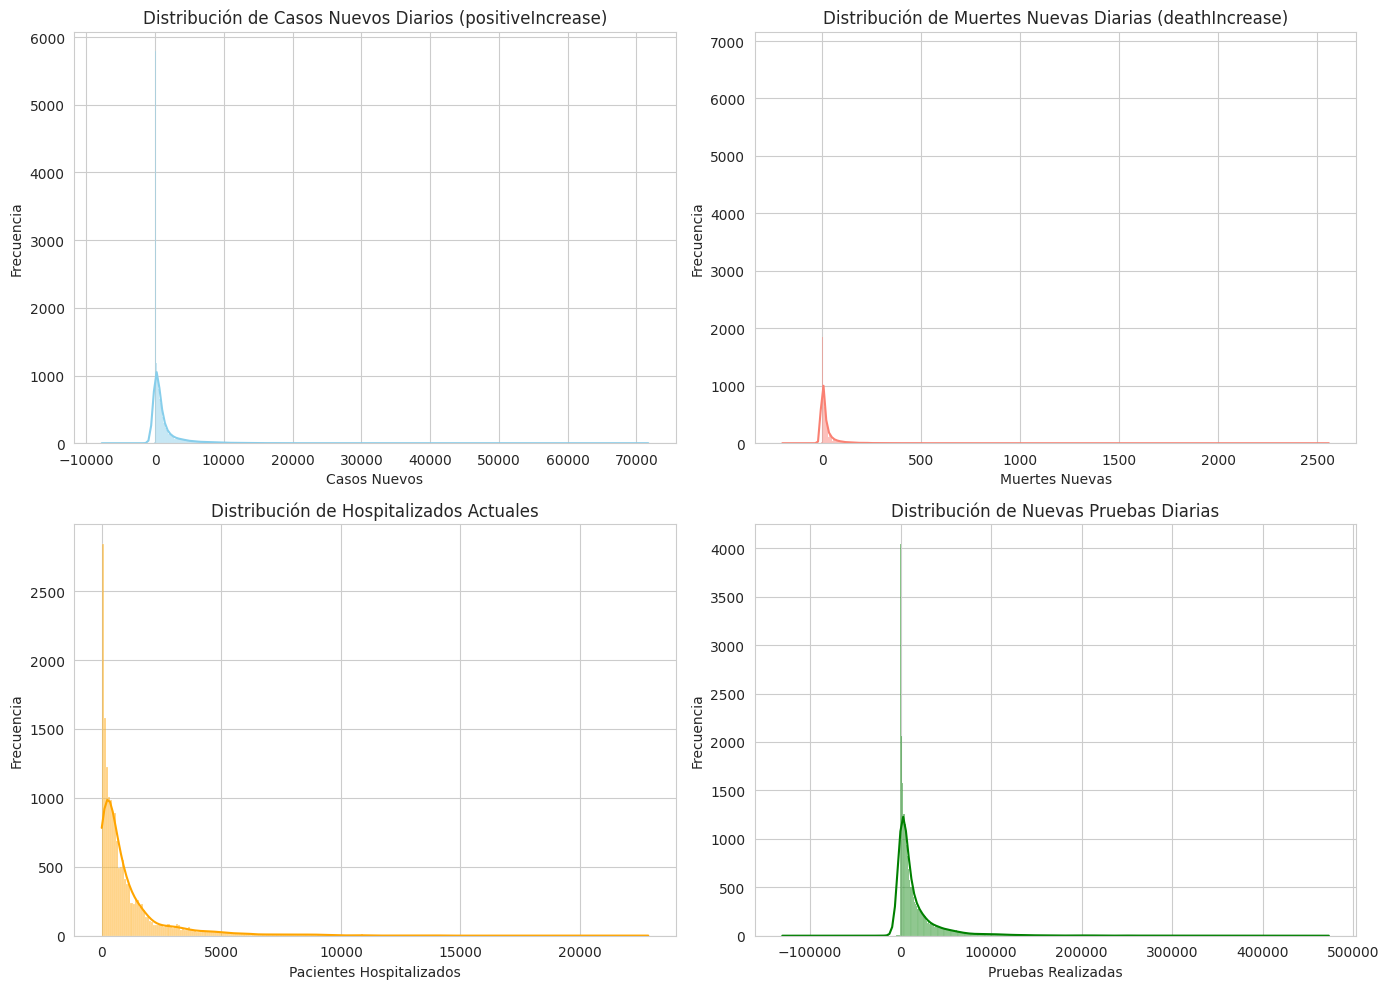

In [ ]:
# Configuramos una figura con subplots para ver las distribuciones principales
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Casos nuevos diarios (positiveIncrease)
sns.histplot(df_clean['positiveIncrease'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Distribución de Casos Nuevos Diarios (positiveIncrease)')
axes[0, 0].set_xlabel('Casos Nuevos')
axes[0, 0].set_ylabel('Frecuencia')

# 2. Muertes nuevas diarias (deathIncrease)
sns.histplot(df_clean['deathIncrease'], kde=True, ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Distribución de Muertes Nuevas Diarias (deathIncrease)')
axes[0, 1].set_xlabel('Muertes Nuevas')
axes[0, 1].set_ylabel('Frecuencia')

# 3. Hospitalizados actuales (hospitalizedCurrently)
sns.histplot(df_clean['hospitalizedCurrently'].dropna(), kde=True, ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Distribución de Hospitalizados Actuales')
axes[1, 0].set_xlabel('Pacientes Hospitalizados')
axes[1, 0].set_ylabel('Frecuencia')

# 4. Total de resultados de pruebas diarias (totalTestResultsIncrease)
sns.histplot(df_clean['totalTestResultsIncrease'], kde=True, ax=axes[1, 1], color='green')
axes[1, 1].set_title('Distribución de Nuevas Pruebas Diarias')
axes[1, 1].set_xlabel('Pruebas Realizadas')
axes[1, 1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

## 7. Análisis Temporal: Evolución de la Pandemia en EE.UU.
Convertimos la columna de fecha a tipo datetime, ordenamos cronológicamente y agregamos los datos a nivel nacional por día para observar las distintas Olas de contagios y muertes.

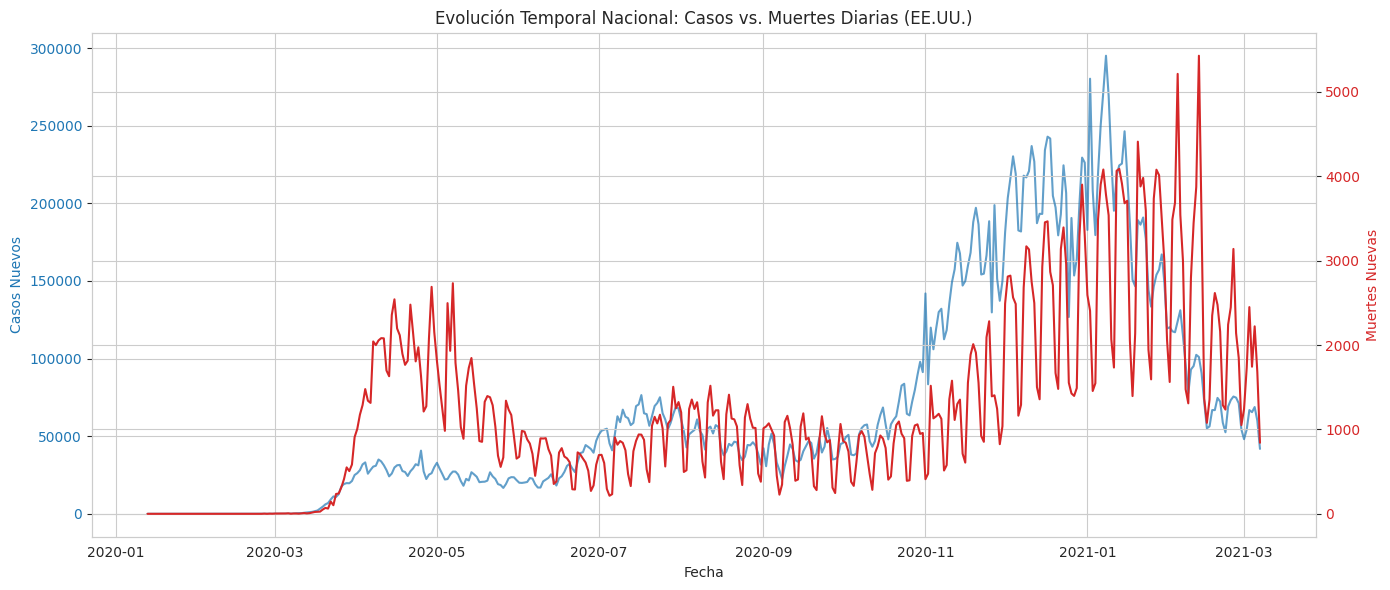

In [ ]:
# Convertir la columna date a datetime (el formato original es d-m-Y o similar, revisamos el string: '07-03-2021')
df_clean['date_dt'] = pd.to_datetime(df_clean['date'], format='%d-%m-%Y', errors='coerce')

# Agrupar a nivel nacional (sumando todos los estados por fecha)
df_temporal = df_clean.groupby('date_dt')[['positiveIncrease', 'deathIncrease', 'hospitalizedCurrently']].sum().reset_index()
df_temporal = df_temporal.sort_values('date_dt')

# Gráfico de serie temporal para Casos y Muertes diarias
fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(df_temporal['date_dt'], df_temporal['positiveIncrease'], color='tab:blue', label='Casos Nuevos Diarios', alpha=0.7)
ax1.set_xlabel('Fecha')
ax1.set_ylabel('Casos Nuevos', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(df_temporal['date_dt'], df_temporal['deathIncrease'], color='tab:red', label='Muertes Nuevas Diarias', linewidth=1.5)
ax2.set_ylabel('Muertes Nuevas', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Evolución Temporal Nacional: Casos vs. Muertes Diarias (EE.UU.)')
fig.tight_layout()
plt.show()

## 8. Análisis Bivariado: Comparativa por Estados (Top 10)
Identificamos cuáles son los estados con mayor impacto acumulado de casos y muertes por COVID-19.

/tmp/ipykernel_1980/2934068911.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_cases, x='state', y='positive', palette='Blues_r')


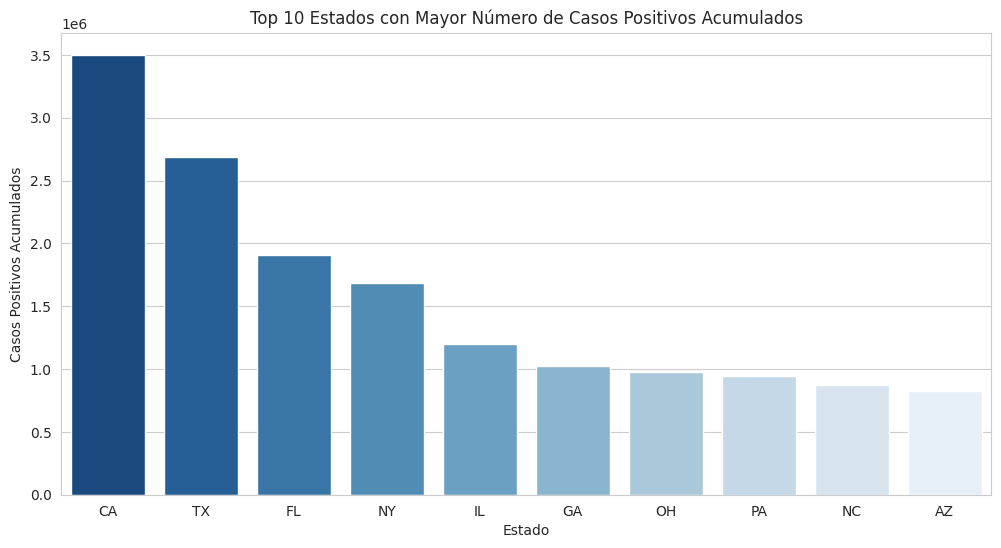

/tmp/ipykernel_1980/2934068911.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_deaths, x='state', y='death', palette='Reds_r')


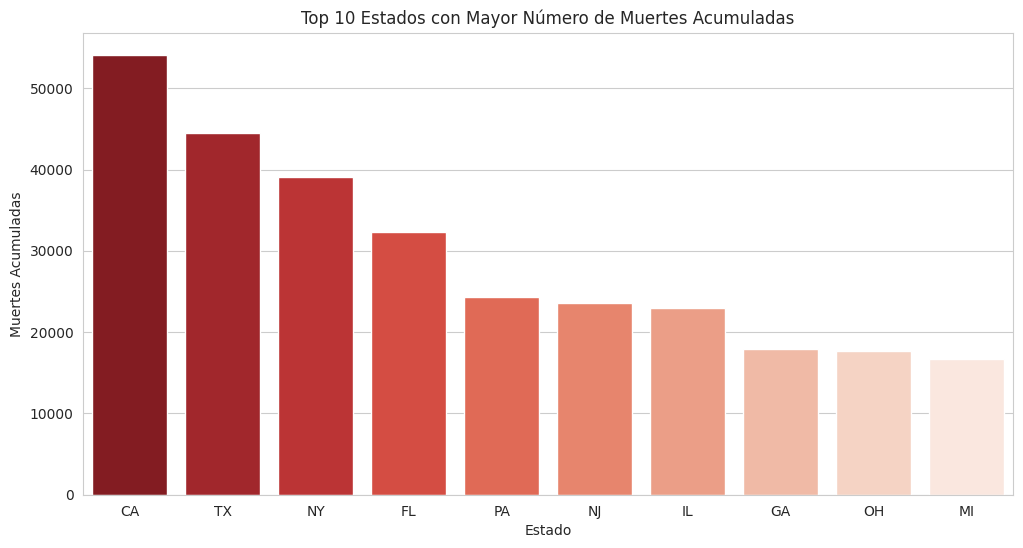

In [ ]:
# Tomamos el registro más actualizado por cada estado (o el acumulado máximo)
df_states_max = df_clean.groupby('state')[['positive', 'death']].max().reset_index()

# Top 10 estados con más casos positivos acumulados
top_10_cases = df_states_max.sort_values(by='positive', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_cases, x='state', y='positive', palette='Blues_r')
plt.title('Top 10 Estados con Mayor Número de Casos Positivos Acumulados')
plt.xlabel('Estado')
plt.ylabel('Casos Positivos Acumulados')
plt.show()

# Top 10 estados con más muertes acumuladas
top_10_deaths = df_states_max.sort_values(by='death', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_deaths, x='state', y='death', palette='Reds_r')
plt.title('Top 10 Estados con Mayor Número de Muertes Acumuladas')
plt.xlabel('Estado')
plt.ylabel('Muertes Acumuladas')
plt.show()

## 8.1. Análisis Bivariado Normalizado: Tasas por 100.000 Habitantes
Para evitar el sesgo del tamaño poblacional, calculamos la tasa de casos positivos y muertes acumuladas por cada 100.000 habitantes, permitiendo una comparación real del impacto entre los distintos estados.

/tmp/ipykernel_1980/873085813.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_cases_100k, x='state', y='cases_per_100k', palette='Purples_r')


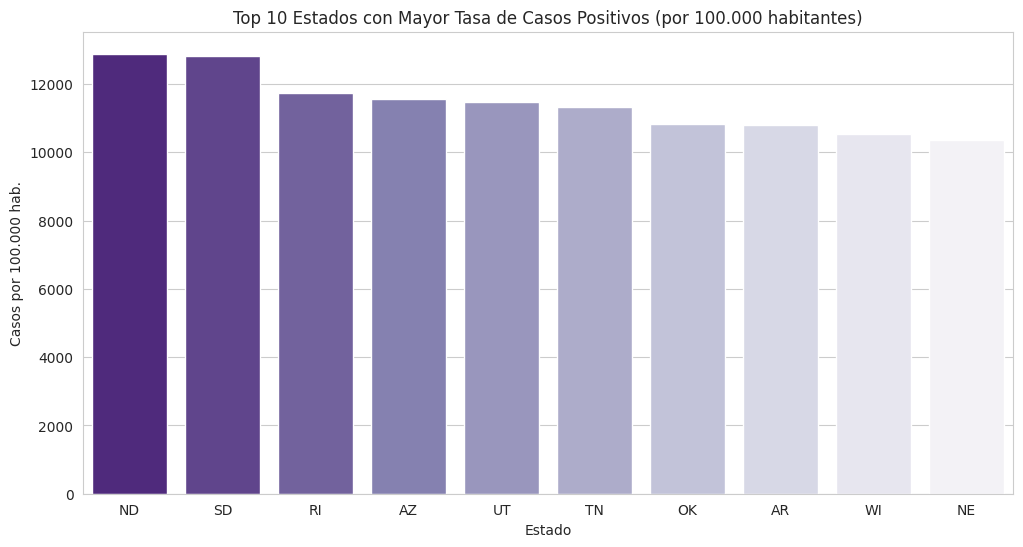

/tmp/ipykernel_1980/873085813.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_deaths_100k, x='state', y='deaths_per_100k', palette='Oranges_r')


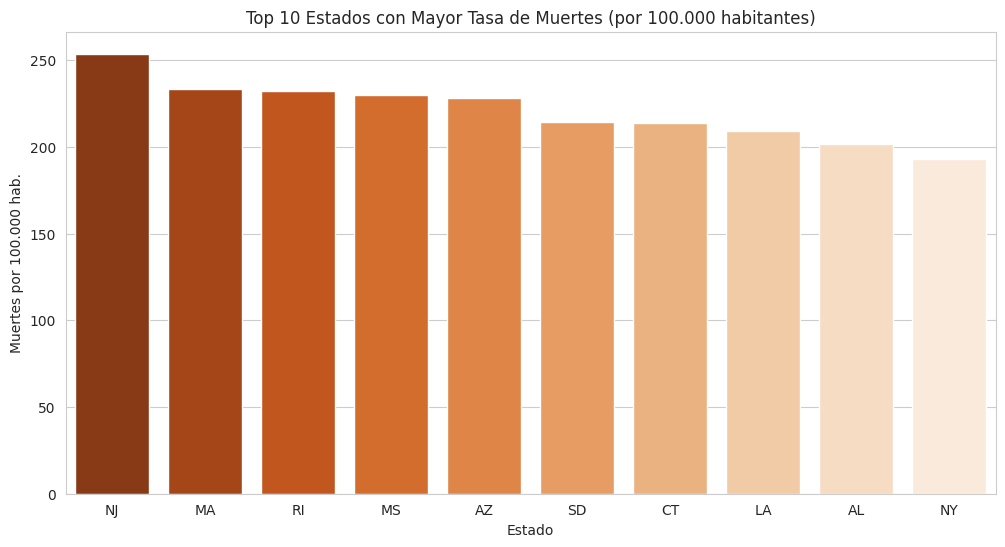

In [ ]:
# 1. Diccionario de población de referencia por estado (Aproximación Censo EE.UU. 2020-2021)
state_populations = {
    'CA': 39538223, 'TX': 29145505, 'FL': 21538187, 'NY': 20201249,
    'PA': 13002700, 'IL': 12812508, 'OH': 11799448, 'GA': 10711908,
    'NC': 10439388, 'MI': 10077331, 'NJ': 9288994, 'VA': 8631393,
    'WA': 7705281, 'AZ': 7151502, 'MA': 7029917, 'TN': 6910840,
    'IN': 6785528, 'MO': 6154913, 'MD': 6177224, 'WI': 5893718,
    'CO': 5773714, 'MN': 5706494, 'SC': 5118425, 'AL': 5024279,
    'LA': 4657757, 'KY': 4505836, 'OR': 4237256, 'OK': 3959353,
    'CT': 3605944, 'UT': 3271616, 'IA': 3190369, 'NV': 3104614,
    'AR': 3011524, 'MS': 2961279, 'KS': 2937880, 'NM': 2117522,
    'NE': 1961504, 'ID': 1839106, 'WV': 1793716, 'HI': 1455271,
    'NH': 1377529, 'ME': 1362359, 'RI': 1097379, 'MT': 1084225,
    'DE': 989948, 'SD': 886667, 'ND': 779094, 'AK': 733391,
    'VT': 643077, 'WY': 576851, 'DC': 689545
}

# 2. Obtenemos el valor máximo acumulado por estado
df_states_max = df_clean.groupby('state')[['positive', 'death']].max().reset_index()

# 3. Mapeamos la población al DataFrame de estados
df_states_max['population'] = df_states_max['state'].map(state_populations)

# 4. Calculamos las tasas por 100,000 habitantes
df_states_max['cases_per_100k'] = (df_states_max['positive'] / df_states_max['population']) * 100000
df_states_max['deaths_per_100k'] = (df_states_max['death'] / df_states_max['population']) * 100000

# 5. Visualización: Top 10 Estados con más Casos por 100k hab.
top_10_cases_100k = df_states_max.sort_values(by='cases_per_100k', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_cases_100k, x='state', y='cases_per_100k', palette='Purples_r')
plt.title('Top 10 Estados con Mayor Tasa de Casos Positivos (por 100.000 habitantes)')
plt.xlabel('Estado')
plt.ylabel('Casos por 100.000 hab.')
plt.show()

# 6. Visualización: Top 10 Estados con más Muertes por 100k hab.
top_10_deaths_100k = df_states_max.sort_values(by='deaths_per_100k', ascending=False).head(10)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_10_deaths_100k, x='state', y='deaths_per_100k', palette='Oranges_r')
plt.title('Top 10 Estados con Mayor Tasa de Muertes (por 100.000 habitantes)')
plt.xlabel('Estado')
plt.ylabel('Muertes por 100.000 hab.')
plt.show()

/tmp/ipykernel_1980/1295609292.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_cases_tot, x='state', y='positive', ax=axes[0, 0], palette='Blues_r')
/tmp/ipykernel_1980/1295609292.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_cases_100k, x='state', y='positive_per_100k', ax=axes[0, 1], palette='Blues_r')
/tmp/ipykernel_1980/1295609292.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_deaths_tot, x='state', y='death', ax=axes[1, 0], palette='Reds_r')
/tmp/ipykernel_1980/1295609292.py:46: FutureWarning

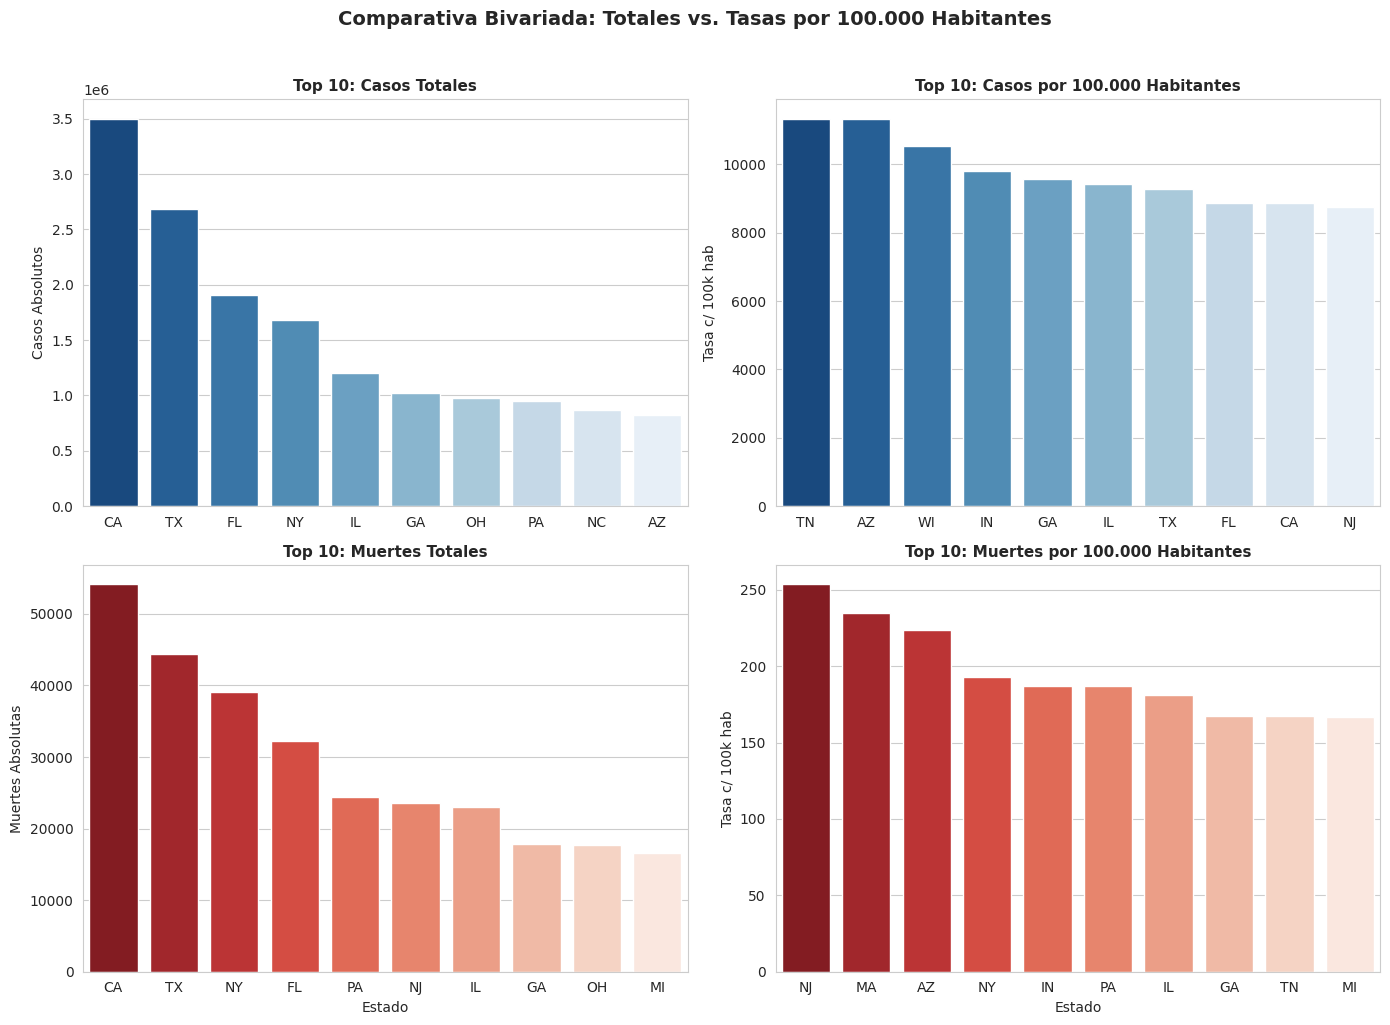

In [ ]:
# 0. Diccionario de población aproximada por estado (ejemplo para los principales / estándar)
# Puedes ampliarlo o cargarlo desde un CSV auxiliar si lo prefieres
poblacion_estados = {
    'CA': 39500000, 'TX': 29000000, 'FL': 21500000, 'NY': 20200000,
    'PA': 13000000, 'IL': 12700000, 'OH': 11700000, 'GA': 10700000,
    'NC': 10400000, 'MI': 10000000, 'NJ': 9300000,  'VA': 8600000,
    'WA': 7700000,  'AZ': 7300000,  'MA': 7000000,  'TN': 6900000,
    'IN': 6800000,  'MO': 6200000,  'MD': 6200000,  'WI': 5900000
    # Nota: Si tu dataset tiene más estados, asegúrate de incluir su población o hacer un merge con un dataset censal.
}

# Creamos una copia para el cálculo por 100k hab
df_analisis = df_clean.groupby('state')[['positive', 'death']].max().reset_index()
df_analisis['poblacion'] = df_analisis['state'].map(poblacion_estados)

# Calculamos tasas por 100,000 habitantes
df_analisis['positive_per_100k'] = (df_analisis['positive'] / df_analisis['poblacion']) * 100000
df_analisis['death_per_100k'] = (df_analisis['death'] / df_analisis['poblacion']) * 100000

# Configuramos una figura compacta de 2x2 subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Casos Totales (Top 10)
top_cases_tot = df_analisis.sort_values(by='positive', ascending=False).head(10)
sns.barplot(data=top_cases_tot, x='state', y='positive', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Top 10: Casos Totales', fontsize=11, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Casos Absolutos')

# 2. Casos por 100k Habitantes (Top 10)
top_cases_100k = df_analisis.sort_values(by='positive_per_100k', ascending=False).head(10)
sns.barplot(data=top_cases_100k, x='state', y='positive_per_100k', ax=axes[0, 1], palette='Blues_r')
axes[0, 1].set_title('Top 10: Casos por 100.000 Habitantes', fontsize=11, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Tasa c/ 100k hab')

# 3. Muertes Totales (Top 10)
top_deaths_tot = df_analisis.sort_values(by='death', ascending=False).head(10)
sns.barplot(data=top_deaths_tot, x='state', y='death', ax=axes[1, 0], palette='Reds_r')
axes[1, 0].set_title('Top 10: Muertes Totales', fontsize=11, fontweight='bold')
axes[1, 0].set_xlabel('Estado')
axes[1, 0].set_ylabel('Muertes Absolutas')

# 4. Muertes por 100k Habitantes (Top 10)
top_deaths_100k = df_analisis.sort_values(by='death_per_100k', ascending=False).head(10)
sns.barplot(data=top_deaths_100k, x='state', y='death_per_100k', ax=axes[1, 1], palette='Reds_r')
axes[1, 1].set_title('Top 10: Muertes por 100.000 Habitantes', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Estado')
axes[1, 1].set_ylabel('Tasa c/ 100k hab')

# Ajustes visuales generales
plt.suptitle('Comparativa Bivariada: Totales vs. Tasas por 100.000 Habitantes', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 9. Análisis Multivariado: Matriz de Correlación
Calculamos la matriz de correlación de Pearson para identificar asociaciones fuertes entre pruebas, hospitalizaciones, casos y muertes.

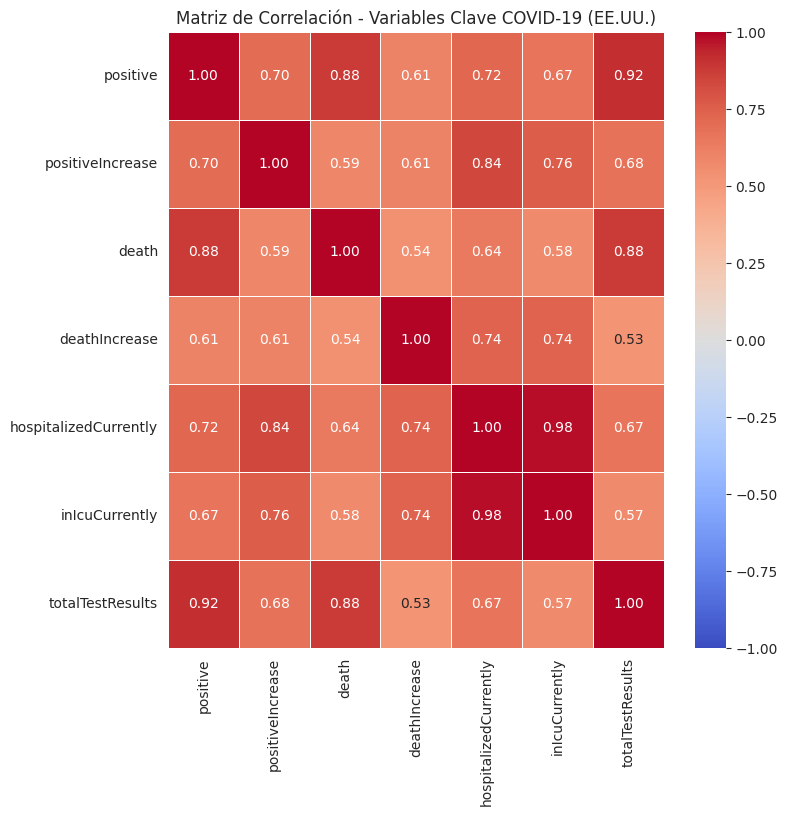

In [ ]:
# 1. Selección de variables cuantitativas clave para el análisis
cols_corr = ['positive', 'positiveIncrease', 'death', 'deathIncrease',
             'hospitalizedCurrently', 'inIcuCurrently', 'totalTestResults']

# 2. Cálculo de la matriz de correlación de Pearson
corr_matrix = df_clean[cols_corr].corr()

# 3. Representación visual mediante un mapa de calor (Heatmap)
plt.figure(figsize=(8, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de Correlación - Variables Clave COVID-19 (EE.UU.)')
plt.show()

## 10. Detección de Outliers
Utilizamos diagramas de caja para visualizar la dispersión y los valores atípicos (picos máximos de contagios o retrasos en la carga de datos que generan valores negativos).

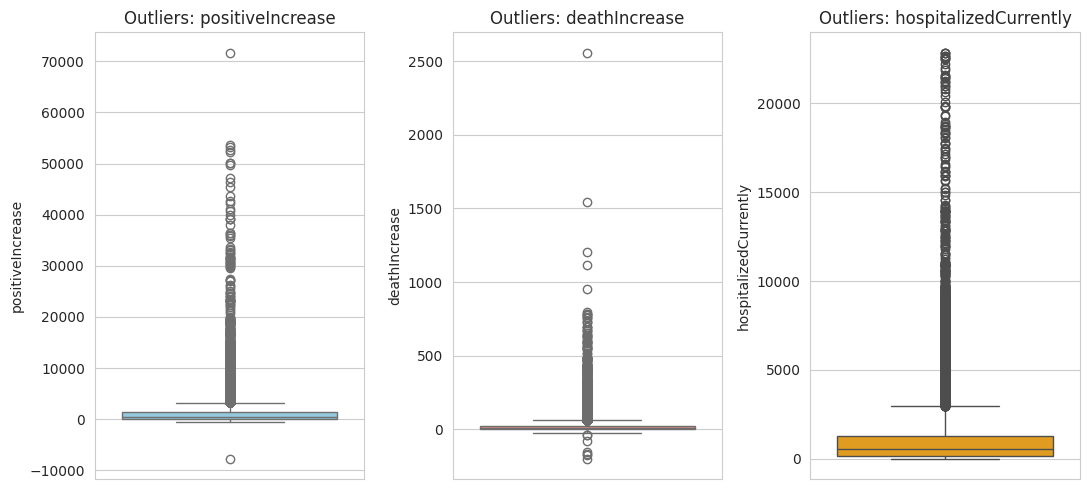

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 5))

sns.boxplot(y=df_clean['positiveIncrease'], ax=axes[0], color='skyblue')
axes[0].set_title('Outliers: positiveIncrease')

sns.boxplot(y=df_clean['deathIncrease'], ax=axes[1], color='salmon')
axes[1].set_title('Outliers: deathIncrease')

sns.boxplot(y=df_clean['hospitalizedCurrently'], ax=axes[2], color='orange')
axes[2].set_title('Outliers: hospitalizedCurrently')

plt.tight_layout()
plt.show()

Rango Intercuartílico (IQR)

In [ ]:
# Definimos una función genérica o aplicamos directamente la lógica sobre 'positiveIncrease'
columna = 'positiveIncrease'

Q1 = df_clean[columna].quantile(0.25)
Q3 = df_clean[columna].quantile(0.75)
IQR = Q3 - Q1

# Definir los límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Límite inferior: {limite_inferior}")
print(f"Límite superior: {limite_superior}")

# Opción A: Filtrar el DataFrame eliminando los outliers
df_sin_outliers = df_clean[(df_clean[columna] >= limite_inferior) & (df_clean[columna] <= limite_superior)]

# Opción B: Técnica de Winsorization (limitar los valores extremos al tope superior en vez de borrarlos)
# df_clean[columna] = np.where(df_clean[columna] > limite_superior, limite_superior, df_clean[columna])

Límite inferior: -1840.375
Límite superior: 3240.625
